Getting familiar with Linear Regression 
Objective: Predicting daily bike rental counts based on weather, temperature and time.
Dataset: day.csv

In [2]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

# Retrieve dataset
rentals = pd.read_csv("day.csv")
rentals.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
day_of_year = pd.to_datetime(rentals["dteday"]).apply(lambda dt: (dt-datetime(dt.year,1,1)).days)

weather = rentals["weathersit"]
temperature = rentals["temp"]

casual = rentals["casual"]
registered = rentals["registered"]
count = rentals["cnt"]

new_rentals = pd.DataFrame({
    "Day of the year": day_of_year,
    "Weather": weather,
    "Temperature": temperature,
    "Casual Users": casual,
    "Registered Users": registered,
    "Total Rental Count": count})

new_rentals.head()

,Day of the year,Weather,Temperature,Casual Users,Registered Users,Total Rental Count
0,0,2,0.344167,331,654,985
1,1,2,0.363478,131,670,801
2,2,1,0.196364,120,1229,1349
3,3,1,0.200000,108,1454,1562
4,4,1,0.226957,82,1518,1600


<Axes: xlabel='Day of the year', ylabel='Total Rental Count'>

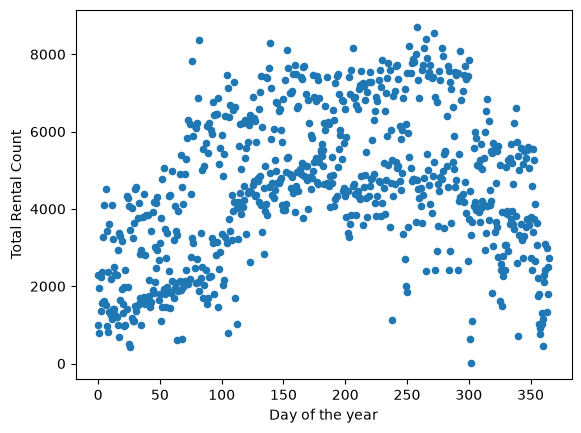

In [4]:
new_rentals.plot.scatter("Day of the year","Total Rental Count")

In [5]:
# Importing Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [6]:
# 1
X = new_rentals[["Day of the year", "Weather", "Temperature"]]
y = new_rentals["Total Rental Count"]

# 2 - Separating input values (features) and the expected output (labels) into separate numpy arrays
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# 3 - Define the LinearRegression object and fit it to the data using the fit() method
lin_reg = LinearRegression() # Create linear regression
lin_reg.fit(X_train,y_train) # Fit the linear regression

# 4 - View the value of coffecients
print ("Intercept value: ", lin_reg.intercept_) # View the intercept value

# 5 - View the feature coefficient
print ("Slope value: ", lin_reg.coef_)

# 6 - Predict the target value
pred = lin_reg.predict(X_test)
mse = np.sqrt(mean_squared_error(y_test,pred))
print(f"Root Mean Square Error: {mse:3.3} ({mse/np.mean(pred) * 100:3.3}%)")

# 7 - Coefficient of determination
score = lin_reg.score(X_train,y_train)
print("Model determination (R² score): ", score) 

Intercept value:  2024.6268242180481
Slope value:  [ 3.09276082e+00 -7.54096995e+02  6.00529920e+03]
Root Mean Square Error: 1.53e+03 (33.5%)
Model determination (R² score):  0.4740156574570319


In [8]:
lin_reg.coef_, lin_reg.intercept_
lin_reg.predict(pd.DataFrame({"Day of the year": [180], "Weather": [1], "Temperature": [0.6]}))

array([5430.40629873])

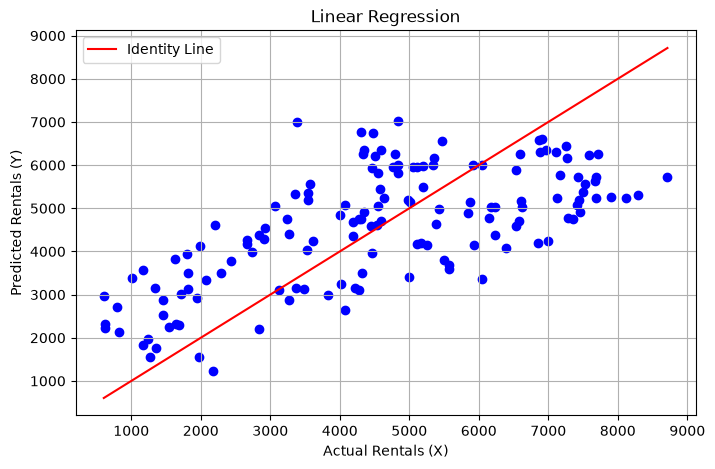

In [9]:
# 8 - Creating a graph to visualise the data
plt.figure(figsize = (8,5))
plt.scatter(y_test, pred, color = "Blue")
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    label = "Identity Line",
    color = "Red",
)
plt.title("Linear Regression")
plt.xlabel("Actual Rentals (X)")
plt.ylabel("Predicted Rentals (Y)")
plt.grid(True)
plt.legend()
plt.show()